# Monday

Standartizatoin of the model weights, bsically need to include regularization of the weights since some features might not be on the same scale.

In [37]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge

from sklearn.metrics import r2_score

In [38]:
X = 6 * np.random.rand(40, 1) - 3

y = 0.6 * X**2 + 0.5 * X + 5 + np.random.randn(40, 1)

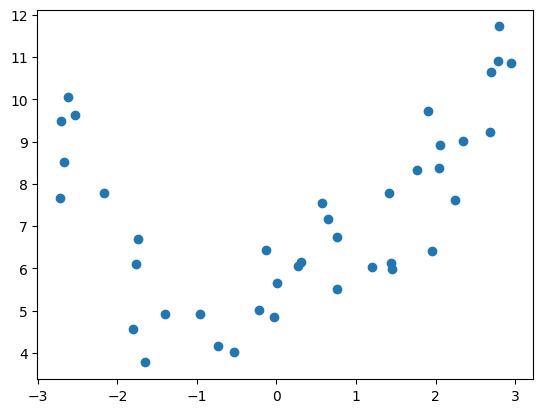

In [39]:
plt.scatter(X, y)


In [40]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [41]:
# Create polynomial features
poly = PolynomialFeatures(degree=15, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [42]:
model = LinearRegression()
model.fit(X_train_poly, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [43]:
# predict my train dataset and test dataset

train_pred = model.predict(X_train_poly)
test_pred = model.predict(X_test_poly)

In [44]:
# Get r2 score
print("Train R2:", r2_score(y_train, train_pred))
print("Test R2:", r2_score(y_test, test_pred))


Train R2: 0.9132779980346094
Test R2: -0.2938974066198816


In [45]:
scaler = StandardScaler()

X_train_scaler = scaler.fit_transform(X_train_poly)
X_test_scaler = scaler.transform(X_test_poly)

Ridge Train R2: 0.7496354697171831
Ridge Test R2: 0.4415218741688437


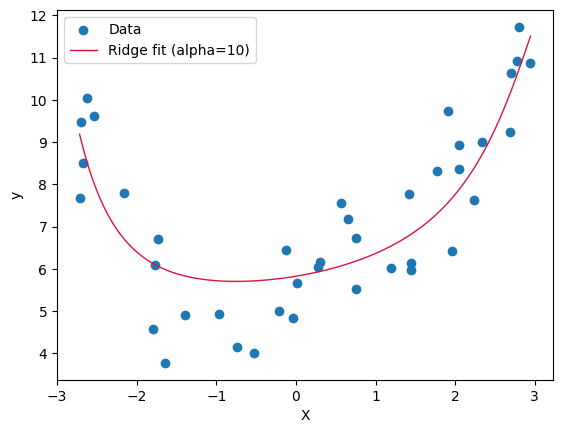

In [46]:
# Ridge regression on the standardized polynomial features
ridge_model = Ridge(alpha=10)
ridge_model.fit(X_train_scaler, y_train)

ridge_train_pred = ridge_model.predict(X_train_scaler)
ridge_test_pred = ridge_model.predict(X_test_scaler)

print("Ridge Train R2:", r2_score(y_train, ridge_train_pred))
print("Ridge Test R2:", r2_score(y_test, ridge_test_pred))

# Plot the Ridge regression curve
X_plot = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
X_plot_poly = poly.transform(X_plot)
X_plot_scaled = scaler.transform(X_plot_poly)
y_plot = ridge_model.predict(X_plot_scaled)

plt.scatter(X, y, label="Data")
plt.plot(X_plot, y_plot, color="crimson", linewidth=1, label=f"Ridge fit (alpha={ridge_model.alpha})")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

In [47]:
print(ridge_model.coef_)

[ 0.60041596  0.55679823  0.12815524  0.4663308  -0.01305307  0.33287503
 -0.05785881  0.21517318 -0.06742358  0.11946075 -0.06679349  0.04221586
 -0.06628691 -0.02055228 -0.06960643]


# Wednesday

Something somethig sigmoid function that keeps eveything in 0 - 1.

sigmoid(z) = 1 / (1 + e^(-z))
- Large negative z gives about 0, large positive z gives about 1, and z = 0 gives 0.5. That's the "keeps everything in 0 - 1" part, and it is logistic regression.



## Sigmoid

The linear model gives a score $z$, and the sigmoid turns it into a probability $p$:

$$z = w^\top x + b, \qquad p = \sigma(z) = \frac{1}{1 + e^{-z}}, \qquad p = P(y = 1 \mid x)$$

Its derivative (used later for the gradients):

$$\sigma'(z) = \sigma(z)\,(1 - \sigma(z))$$

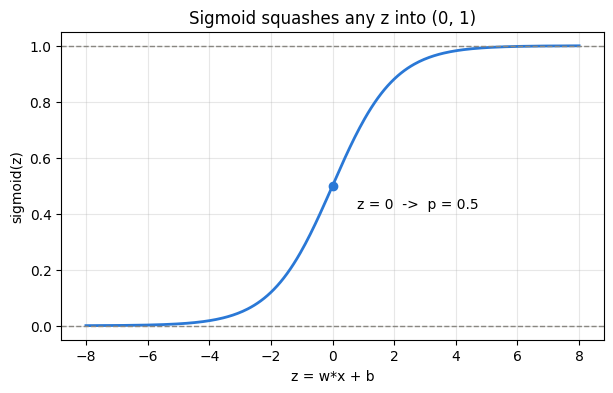

In [48]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#898781"

z = np.linspace(-8, 8, 300)

plt.figure(figsize=(7, 4))
plt.plot(z, sigmoid(z), color=BLUE, linewidth=2)
plt.axhline(0, color=GRAY, linewidth=1, linestyle="--")
plt.axhline(1, color=GRAY, linewidth=1, linestyle="--")
plt.scatter([0], [0.5], color=BLUE, zorder=3)
plt.annotate("z = 0  ->  p = 0.5", (0, 0.5), xytext=(0.8, 0.42))
plt.xlabel("z = w*x + b")
plt.ylabel("sigmoid(z)")
plt.title("Sigmoid squashes any z into (0, 1)")
plt.grid(alpha=0.3)
plt.show()

## Loss L for one example (log loss / binary cross-entropy)

For one example with true label $y \in \{0, 1\}$ and predicted probability $p$:

$$L(y, p) = -\Big[\, y \log p + (1 - y) \log (1 - p) \,\Big]$$

Only one of the two terms is ever active:

$$L = \begin{cases} -\log p & \text{if } y = 1 \\ -\log (1 - p) & \text{if } y = 0 \end{cases}$$

Confident and right gives $L \approx 0$. Confident and wrong gives $L \to \infty$ (for example $y = 1$, $p = 0.01$ gives $L = -\log 0.01 \approx 4.6$).

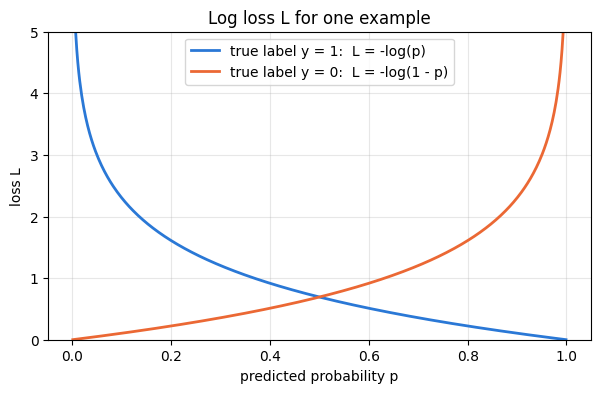

In [49]:
p = np.linspace(0.001, 0.999, 500)

plt.figure(figsize=(7, 4))
plt.plot(p, -np.log(p), color=BLUE, linewidth=2, label="true label y = 1:  L = -log(p)")
plt.plot(p, -np.log(1 - p), color=ORANGE, linewidth=2, label="true label y = 0:  L = -log(1 - p)")
plt.ylim(0, 5)
plt.xlabel("predicted probability p")
plt.ylabel("loss L")
plt.title("Log loss L for one example")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Convexity: loss L as a function of the weight w

A function $f$ is **convex** if the straight line between any two points on its graph never goes below the graph:

$$f(\lambda a + (1 - \lambda) b) \;\le\; \lambda f(a) + (1 - \lambda) f(b), \qquad 0 \le \lambda \le 1$$

For a smooth 1-D function this is the same as $f''(w) \ge 0$ everywhere (always curving upward). A convex function has one bowl, so any minimum gradient descent finds is the global one.

Total loss over $n$ examples, with $p_i = \sigma(w x_i)$ (no bias here, so $L$ depends on a single $w$ and can be plotted):

$$L_{\text{log}}(w) = -\frac{1}{n} \sum_{i=1}^{n} \Big[\, y_i \log p_i + (1 - y_i) \log (1 - p_i) \,\Big]$$

$$L_{\text{MSE}}(w) = \frac{1}{n} \sum_{i=1}^{n} \big( y_i - p_i \big)^2$$

Why log loss is convex: the log undoes the exponential inside the sigmoid,

$$-\log \sigma(z) = \log\!\left(1 + e^{-z}\right), \qquad \frac{d^2}{dz^2} \log\!\left(1 + e^{-z}\right) = \sigma(z)\,(1 - \sigma(z)) > 0$$

The second derivative is always positive, so each term is convex, and a sum of convex terms is convex. Squaring the sigmoid instead does not cancel its S-shape, so $L_{\text{MSE}}$ is not convex.

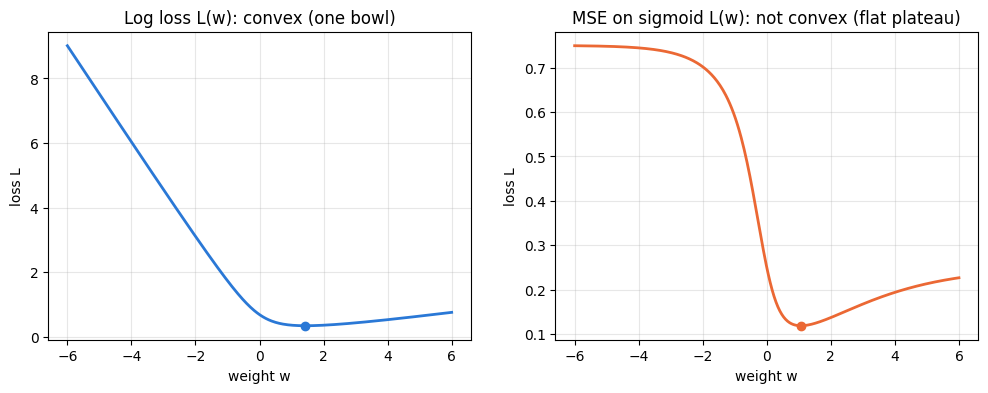

In [50]:
# tiny 1-feature classification dataset (two points are on the "wrong side" so it is not perfectly separable)
x_c = np.array([-3, -2, -1, -0.5, 0.5, 1, 2, 3])
y_c = np.array([ 0,  0,  0,    1,   0, 1, 1, 1])

def log_loss_L(w):
    p = sigmoid(w * x_c)
    return -np.mean(y_c * np.log(p) + (1 - y_c) * np.log(1 - p))

def mse_L(w):
    p = sigmoid(w * x_c)
    return np.mean((y_c - p) ** 2)

w_grid = np.linspace(-6, 6, 400)
L_log = np.array([log_loss_L(w) for w in w_grid])
L_mse = np.array([mse_L(w) for w in w_grid])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(w_grid, L_log, color=BLUE, linewidth=2)
axes[0].scatter(w_grid[L_log.argmin()], L_log.min(), color=BLUE, zorder=3)
axes[0].set_title("Log loss L(w): convex (one bowl)")

axes[1].plot(w_grid, L_mse, color=ORANGE, linewidth=2)
axes[1].scatter(w_grid[L_mse.argmin()], L_mse.min(), color=ORANGE, zorder=3)
axes[1].set_title("MSE on sigmoid L(w): not convex (flat plateau)")

for ax in axes:
    ax.set_xlabel("weight w")
    ax.set_ylabel("loss L")
    ax.grid(alpha=0.3)
plt.show()

## Gradients: why the plateau traps gradient descent

Gradient descent update, with learning rate $\eta$:

$$w \leftarrow w - \eta \, \frac{\partial L}{\partial w}$$

Using $\sigma'(z) = \sigma(z)\,(1 - \sigma(z))$, the two gradients are:

$$\frac{\partial L_{\text{log}}}{\partial w} = \frac{1}{n} \sum_{i=1}^{n} (p_i - y_i)\, x_i$$

$$\frac{\partial L_{\text{MSE}}}{\partial w} = \frac{1}{n} \sum_{i=1}^{n} 2\,(p_i - y_i)\; p_i (1 - p_i)\; x_i$$

The log loss gradient is just (error) $\times$ (input), the same form as linear regression. The MSE gradient has an extra factor $p_i(1 - p_i)$, which goes to 0 when the sigmoid saturates ($p_i$ near 0 or 1). So when the model is confidently wrong, the MSE gradient is almost zero and $w$ barely moves.

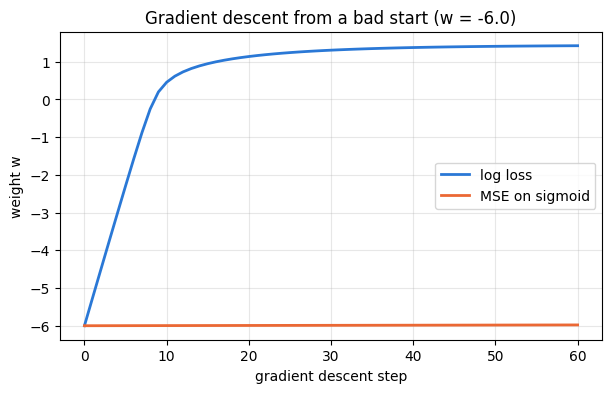

final w, log loss: 1.425957994680846
final w, MSE:      -5.978746349130062


In [51]:
def grad_log(w):
    p = sigmoid(w * x_c)
    return np.mean((p - y_c) * x_c)

def grad_mse(w):
    p = sigmoid(w * x_c)
    return np.mean(2 * (p - y_c) * p * (1 - p) * x_c)

lr, steps, w_start = 0.5, 60, -6.0
w_log, w_mse = [w_start], [w_start]
for _ in range(steps):
    w_log.append(w_log[-1] - lr * grad_log(w_log[-1]))
    w_mse.append(w_mse[-1] - lr * grad_mse(w_mse[-1]))

plt.figure(figsize=(7, 4))
plt.plot(w_log, color=BLUE, linewidth=2, label="log loss")
plt.plot(w_mse, color=ORANGE, linewidth=2, label="MSE on sigmoid")
plt.xlabel("gradient descent step")
plt.ylabel("weight w")
plt.title(f"Gradient descent from a bad start (w = {w_start})")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("final w, log loss:", w_log[-1])
print("final w, MSE:     ", w_mse[-1])

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import r2_score

In [53]:
df = pd.read_csv("../../data/lung_cancer_dataset.csv")

In [54]:
df.head()

,patient_id,age,gender,pack_years,radon_exposure,asbestos_exposure,secondhand_smoke_exposure,copd_diagnosis,alcohol_consumption,family_history,lung_cancer
0,100000,69,Male,66.025244,High,No,No,Yes,Moderate,No,No
1,100001,32,Female,12.780800,High,No,Yes,Yes,Moderate,Yes,Yes
2,100002,89,Female,0.408278,Medium,Yes,Yes,Yes,NaN,No,Yes
3,100003,78,Female,44.065232,Low,No,Yes,No,Moderate,No,Yes
4,100004,38,Female,44.432440,Medium,Yes,No,Yes,NaN,Yes,Yes


In [55]:
df['lung_cancer'].value_counts()

lung_cancer
Yes    34364
No     15636
Name: count, dtype: int64

In [56]:
X = df[["age", "pack_years"]]
y = df["lung_cancer"].map({"No": 0, "Yes": 1})

In [57]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [58]:
logistic_model = LogisticRegression()
logistic_model.fit(X_train, y_train)

y_prob = logistic_model.predict_proba(X_test)

In [59]:
from sklearn.metrics import log_loss

loss = log_loss(y_test, y_prob)
print("Test Log Loss:", loss)

Test Log Loss: 0.5913162500611645


[[ 459 2659]
 [ 257 6625]]
Test accuracy: 0.7084


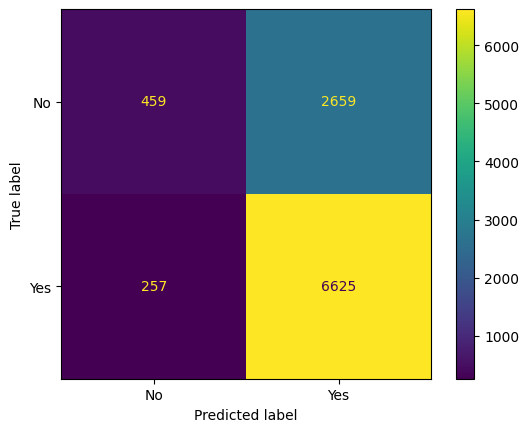

In [62]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# predict() turns the probabilities into 0/1 using a 0.5 threshold
y_pred = logistic_model.predict(X_test)

# rows = true label, columns = predicted label
cm = confusion_matrix(y_test, y_pred)
print(cm)
print("Test accuracy:", accuracy_score(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No", "Yes"])

In [63]:
from sklearn.metrics import balanced_accuracy_score

print("Test balanced accuracy:", balanced_accuracy_score(y_test, y_pred))

Test balanced accuracy: 0.5549329772156646
